# G1.10 · Collectives from first principles: semantics, ring all-reduce, α–β cost, measured bandwidth

**ID:** G1.10 · **Target:** 100 min · **Plan week:** 15 · **Part:** G1

**The lab.** Every parallelism strategy in G1.11-G1.21 is a choice of *which collective runs on which tensor
and when*. This lab builds that vocabulary from scratch on this machine:
1. process groups, ranks, backends, and what `torchrun` sets up for you;
2. the semantics of broadcast / reduce / all-reduce / reduce-scatter / all-gather / all-to-all / scatter /
   gather / send-recv, each shown as a per-rank table and asserted against an analytic answer;
3. the identities that the rest of the track relies on (all-reduce = reduce-scatter + all-gather;
   reduce-scatter = all-to-all + local sum);
4. **ring all-reduce written by you with `send`/`recv`**, checked against `dist.all_reduce` and against the
   $2\frac{N-1}{N}S$ bytes-per-rank bound;
5. the α–β cost model, then a bandwidth sweep (algbw vs busbw, nccl-tests definitions) with a fitted α and β
   for this PCIe box, contrasted with NVLink/NVSwitch H100 nodes.

Guide G1: "Parallelism: data parallel (DDP, all-reduce) ... write a 2-process DDP script with
`torch.distributed`". This lab is the prerequisite; G1.11 is the DDP script.

**How the notebook runs multi-process code.** A Jupyter kernel is one process, so every distributed program is
written to disk by a `%%writefile` cell and launched by `torchrun` in the next cell. Rank 0 saves a small JSON of
results and the notebook checks it. Fill in the `raise NotImplementedError` blocks *inside* the `%%writefile`
cells, re-run the cell to rewrite the file, then re-run the launch cell. The launcher uses all GPUs up to 4 (NCCL),
or 2 CPU processes with Gloo if there are fewer than 2 GPUs. Every check works for any world size ≥ 2.

**This machine (verify in §0):** 4× RTX 3090 on PCIe 4.0 x16, **no NVLink**, and `can_device_access_peer` is
False for every pair. NCCL therefore cannot use GPU-to-GPU P2P and stages traffic through host shared memory
(`NCCL_DEBUG=INFO` prints `via SHM/direct`). You will measure what that costs.

## Sources
- S. Arnold, *Writing Distributed Applications with PyTorch* (PyTorch tutorial; semantics of the collectives and
  a ring all-reduce with `isend`/`recv`): https://docs.pytorch.org/tutorials/intermediate/dist_tuto.html
- `torch.distributed` API reference (collectives, `batch_isend_irecv`, backends table):
  https://docs.pytorch.org/docs/stable/distributed.html · `torchrun` docs: https://docs.pytorch.org/docs/stable/elastic/run.html
- A. Gibiansky, *Bringing HPC Techniques to Deep Learning* (Baidu ring all-reduce), blog, 21 Feb 2017. Data each
  GPU sends is $2(N-1)K/N$, independent of $N$: https://andrew.gibiansky.com/blog/machine-learning/baidu-allreduce/
- R. Thakur, R. Rabenseifner, W. Gropp, *Optimization of Collective Communication Operations in MPICH*, IJHPCA
  19(1), 2005. DOI 10.1177/1094342005051521 (α–β model; ring, recursive doubling, Rabenseifner's
  reduce-scatter + all-gather all-reduce).
- P. Patarasuk, X. Yuan, *Bandwidth optimal all-reduce algorithms for clusters of workstations*, JPDC 69(2), 2009.
  DOI 10.1016/j.jpdc.2008.09.002 (the $2\frac{N-1}{N}S$ lower bound).
- NVIDIA nccl-tests, `doc/PERFORMANCE.md` (algbw = S/t; busbw = algbw × 2(n−1)/n for all-reduce, (n−1)/n for
  reduce-scatter / all-gather / all-to-all, 1 for broadcast / reduce):
  https://github.com/NVIDIA/nccl-tests/blob/master/doc/PERFORMANCE.md
- Stanford CS336 Spring 2026, Assignment 2 (systems), §5.1 benchmarking best practices and §8.1 ring
  reduce-scatter / all-gather analysis. stanford-cs336/assignment2-systems@ca8bc81, MIT. Ideas adapted, prose ours.
- J. Austin, S. Patil, A. Paszke, R. Pope, *How to Scale Your Model*, Part 12 "How to Think About GPUs" (2025):
  H100 NVLink 4 = 18 links × 25 GB/s = 450 GB/s per GPU per direction, ~370 GB/s achieved intra-node all-reduce
  at large sizes, 400 Gb/s (50 GB/s) InfiniBand NIC per GPU: https://jax-ml.github.io/scaling-book/gpus/
- N. Tazi, F. Mom, H. Zhao, P. Nguyen, M. Mekkouri, L. Werra, T. Wolf, *The Ultra-Scale Playbook: Training LLMs
  on GPU Clusters*, Hugging Face, 2025 (appendix A0 "Parallel Programming Crash Course"):
  https://huggingface.co/spaces/nanotron/ultrascale-playbook
- NVIDIA, *Ampere GA102 GPU Architecture* whitepaper v1 (2020): PCIe 4.0 x16 = 64 GB/s peak (both directions,
  so ~32 GB/s each way); RTX 3090 dense bf16 tensor peak 71 TFLOP/s (Table 9):
  https://images.nvidia.com/aem-dam/en-zz/Solutions/geforce/ampere/pdf/NVIDIA-ampere-GA102-GPU-Architecture-Whitepaper-V1.pdf

## 0. Setup and what the hardware looks like
`torchrun` starts one process per GPU and gives each one environment variables: `RANK` (global id),
`WORLD_SIZE`, `LOCAL_RANK` (id within this machine, used to pick the GPU) and `MASTER_ADDR`/`MASTER_PORT`
(a TCP rendezvous store that rank 0 hosts so processes can find each other). `--standalone` picks a free local
port. `dist.init_process_group(backend)` reads those variables. The backend does the data movement:
**NCCL** for CUDA tensors (GPU-initiated, runs on CUDA streams), **Gloo** for CPU tensors.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from prep import Session, check, check_close

s = Session("G1.10", target_min=100)
NGPU = torch.cuda.device_count()
NPROC = min(4, NGPU) if NGPU >= 2 else 2   # world size we launch with
BACKEND = "nccl" if NGPU >= 2 else "gloo"  # <2 GPUs: 2 CPU processes over Gloo
RUN = Path("runs_G1.10")                   # scripts and their JSON results live here, next to this notebook
RUN.mkdir(exist_ok=True)
print(f"{NGPU} GPUs -> NPROC={NPROC}, backend={BACKEND}")


def torchrun(script, *args, nproc=NPROC, timeout=900, env_extra=None):
    """Run `torchrun --standalone --nproc_per_node={nproc} script args` inside RUN/; raise if any rank fails."""
    args = [str(a) for a in args]
    print(f"$ torchrun --standalone --nproc_per_node={nproc} {script} {' '.join(args)}")
    env = {**os.environ, "BACKEND": BACKEND, "OMP_NUM_THREADS": "2", **(env_extra or {})}
    cmd = [sys.executable, "-m", "torch.distributed.run", "--standalone", f"--nproc_per_node={nproc}", script, *args]
    p = subprocess.run(cmd, cwd=RUN, capture_output=True, text=True, timeout=timeout, env=env)
    print(p.stdout)
    if p.returncode != 0:
        print(p.stderr[-6000:])
        raise RuntimeError(f"{script} exited with code {p.returncode}")


def load(name):
    return json.loads((RUN / name).read_text())


if NGPU:
    print(subprocess.run(["nvidia-smi", "topo", "-m"], capture_output=True, text=True).stdout)
    print(subprocess.run(["nvidia-smi", "--query-gpu=index,name,pcie.link.gen.max,pcie.link.width.max",
                          "--format=csv"], capture_output=True, text=True).stdout)
    peer = [[torch.cuda.can_device_access_peer(i, j) if i != j else None for j in range(NGPU)] for i in range(NGPU)]
    print("can_device_access_peer:", peer)

[G1.10] started 16:51; target 100 min
4 GPUs -> NPROC=4, backend=nccl
	GPU0	GPU1	GPU2	GPU3	CPU Affinity	NUMA Affinity	GPU NUMA ID
GPU0	 X 	NODE	NODE	NODE	0-47	0		N/A
GPU1	NODE	 X 	NODE	NODE	0-47	0		N/A
GPU2	NODE	NODE	 X 	NODE	0-47	0		N/A
GPU3	NODE	NODE	NODE	 X 	0-47	0		N/A

Legend:

  X    = Self
  SYS  = Connection traversing PCIe as well as the SMP interconnect between NUMA nodes (e.g., QPI/UPI)
  NODE = Connection traversing PCIe as well as the interconnect between PCIe Host Bridges within a NUMA node
  PHB  = Connection traversing PCIe as well as a PCIe Host Bridge (typically the CPU)
  PXB  = Connection traversing multiple PCIe bridges (without traversing the PCIe Host Bridge)
  PIX  = Connection traversing at most a single PCIe bridge
  NV#  = Connection traversing a bonded set of # NVLinks



index, name, pcie.link.gen.max, pcie.link.width.max
0, NVIDIA GeForce RTX 3090, 4, 16
1, NVIDIA GeForce RTX 3090, 4, 16
2, NVIDIA GeForce RTX 3090, 4, 16
3, NVIDIA GeForce RTX 3090, 4, 16

can_device_access_peer: [[None, False, False, False], [False, None, False, False], [False, False, None, False], [False, False, False, None]]


`NODE` in the topology matrix means traffic between two GPUs crosses PCIe and the host bridges of one CPU socket.
With peer access disabled, NCCL cannot write directly into the other GPU's memory. Each transfer goes
GPU → pinned host buffer → GPU. That is two PCIe crossings, plus a copy through system memory. An 8×H100 SXM node
instead has 18 NVLink-4 links per GPU into 4 NVSwitches: 450 GB/s per GPU per direction (scaling-book Part 12).

A small helper module that every script below imports. Read it: this is the boilerplate of every
`torch.distributed` program.

In [2]:
%%writefile runs_G1.10/dist_utils.py
import json
import os
import time

import torch
import torch.distributed as dist


def setup():
    """Init the default process group from torchrun's env vars and bind this process to its GPU."""
    backend = os.environ.get("BACKEND", "nccl" if torch.cuda.device_count() >= 2 else "gloo")
    local_rank = int(os.environ["LOCAL_RANK"])
    if backend == "nccl":
        dev = torch.device("cuda", local_rank)
        torch.cuda.set_device(dev)                # one GPU per process; without this every rank uses cuda:0
        dist.init_process_group("nccl", device_id=dev)
    else:
        dev = torch.device("cpu")
        dist.init_process_group("gloo")
    return dist.get_rank(), dist.get_world_size(), dev


def sync(dev):
    if dev.type == "cuda":
        torch.cuda.synchronize(dev)               # collectives are async on the GPU: always sync before timing


def bench(fn, dev, warmup=3, iters=10):
    """Median seconds per call of fn() across iters, measured identically on every rank."""
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(iters):
        dist.barrier()
        sync(dev)
        t0 = time.perf_counter()
        fn()
        sync(dev)
        times.append(time.perf_counter() - t0)
    t = torch.tensor([sorted(times)[len(times) // 2]])
    dist.all_reduce(t.to(dev), op=dist.ReduceOp.MAX)  # the slowest rank defines the step
    return float(t.max())


def gather_rows(row):
    """all_gather_object: every rank contributes a picklable object, everyone receives the list (index = rank)."""
    out = [None] * dist.get_world_size()
    dist.all_gather_object(out, row)
    return out


def table(title, cols, rows_per_rank):
    if dist.get_rank() == 0:
        print(f"\n{title}")
        print(" | ".join(f"{c:>18}" for c in ["rank", *cols]))
        for r, row in enumerate(rows_per_rank):
            print(" | ".join(f"{str(v):>18}" for v in [r, *row]))


def fmt(t):
    return str([round(float(v), 2) for v in t.flatten().tolist()])


def save(name, obj):
    if dist.get_rank() == 0:
        with open(name, "w") as f:
            json.dump(obj, f)

Overwriting runs_G1.10/dist_utils.py


## 1. Semantics of the collectives
Notation: $N$ ranks, rank $r$ holds $x_r$. For chunked ops split a tensor into $N$ equal chunks $x_r[0..N-1]$.

```
 broadcast(src=0)       reduce(dst=0)            all_reduce               reduce_scatter
 r0: a  -> a            r0: a -> a+b+c           r0: a -> a+b+c           r0: [a0 a1 a2] -> a0+b0+c0
 r1: b  -> a            r1: b -> (undefined)     r1: b -> a+b+c           r1: [b0 b1 b2] -> a1+b1+c1
 r2: c  -> a            r2: c -> (undefined)     r2: c -> a+b+c           r2: [c0 c1 c2] -> a2+b2+c2

 all_gather             all_to_all (transpose)   scatter(src=0)           gather(dst=0)
 r0: a -> [a b c]       r0: [a0 a1 a2] -> [a0 b0 c0]   r0: [a0 a1 a2] -> a0   r0: a -> [a b c]
 r1: b -> [a b c]       r1: [b0 b1 b2] -> [a1 b1 c1]   r1: -          -> a1   r1: b -> -
 r2: c -> [a b c]       r2: [c0 c1 c2] -> [a2 b2 c2]   r2: -          -> a2   r2: c -> -
```
Point-to-point `send`/`recv` (and the non-blocking `isend`/`irecv`) move one tensor between two named ranks.
Every collective is a **contract all ranks must enter in the same order with matching shapes**. If one rank skips
a call or calls with a different shape, NCCL hangs (or crashes on a watchdog timeout).

**Your task:** fill in the call for each collective. Every rank's input is a deterministic function of its rank,
`x_of(r)`, so the notebook can compute the exact expected answer for every rank. Note which outputs are undefined:
`reduce` only defines the result on `dst`, and NCCL may leave partial sums on the other ranks.

In [3]:
%%writefile runs_G1.10/collectives.py
import torch
import torch.distributed as dist

from dist_utils import fmt, gather_rows, save, setup, table

rank, N, dev = setup()


def x_of(r):  # rank r's input: N numbers, chunk j of it is element j
    return torch.arange(N, dtype=torch.float32, device=dev) + 10 * r


out = {}
x = x_of(rank)

# broadcast from src=0 (in place)
t = x.clone()
dist.broadcast(t, src=0)
out["broadcast"] = t

# reduce (SUM) to dst=0 (in place; only rank 0's result is defined)
t = x.clone()
dist.reduce(t, dst=0, op=dist.ReduceOp.SUM)
out["reduce"] = t

# all_reduce (SUM), and all_reduce (MAX)
t, tmax = x.clone(), x.clone()
dist.all_reduce(t, op=dist.ReduceOp.SUM)
dist.all_reduce(tmax, op=dist.ReduceOp.MAX)
out["all_reduce"], out["all_reduce_max"] = t, tmax

# reduce_scatter (SUM): input N elements, output 1 element per rank. Use dist.reduce_scatter_tensor.
t = torch.empty(1, device=dev)
dist.reduce_scatter_tensor(t, x.clone(), op=dist.ReduceOp.SUM)
out["reduce_scatter"] = t

# all_gather: every rank contributes its N elements, output N*N. Use dist.all_gather_into_tensor.
t = torch.empty(N * N, device=dev)
dist.all_gather_into_tensor(t, x.clone())
out["all_gather"] = t

# all_to_all: chunk j of my input goes to rank j; chunk i of my output came from rank i. Use dist.all_to_all_single.
t = torch.empty(N, device=dev)
dist.all_to_all_single(t, x.clone())
out["all_to_all"] = t

# scatter from src=0: rank r receives chunk r of rank 0's x. Only src passes scatter_list.
t = torch.empty(1, device=dev)
dist.scatter(t, scatter_list=list(x.clone().chunk(N)) if rank == 0 else None, src=0)
out["scatter"] = t

# gather to dst=0: rank 0 receives everyone's x (as a list of N tensors); flatten it into t on rank 0.
t = torch.zeros(N * N, device=dev)
bufs = [torch.empty(N, device=dev) for _ in range(N)] if rank == 0 else None
dist.gather(x.clone(), gather_list=bufs, dst=0)
if rank == 0:
    t = torch.cat(bufs)
out["gather"] = t

# ring shift with point-to-point ops: send x to rank+1, receive from rank-1 (mod N).
# Blocking send on every rank first would deadlock; post both ops together with dist.batch_isend_irecv.
t = torch.empty(N, device=dev)
ops = [dist.P2POp(dist.isend, x.clone(), (rank + 1) % N), dist.P2POp(dist.irecv, t, (rank - 1) % N)]
for req in dist.batch_isend_irecv(ops):
    req.wait()
out["ring_shift"] = t

rows = gather_rows({k: v.cpu().tolist() for k, v in out.items()})
for k in out:
    table(k, ["input", "output"], [[fmt(x_of(r)), fmt(torch.tensor(rows[r][k]))] for r in range(N)])
save("collectives.json", {"N": N, "rows": rows})
dist.destroy_process_group()

Overwriting runs_G1.10/collectives.py


In [4]:
torchrun("collectives.py")

$ torchrun --standalone --nproc_per_node=4 collectives.py 



broadcast
              rank |              input |             output
                 0 | [0.0, 1.0, 2.0, 3.0] | [0.0, 1.0, 2.0, 3.0]
                 1 | [10.0, 11.0, 12.0, 13.0] | [0.0, 1.0, 2.0, 3.0]
                 2 | [20.0, 21.0, 22.0, 23.0] | [0.0, 1.0, 2.0, 3.0]
                 3 | [30.0, 31.0, 32.0, 33.0] | [0.0, 1.0, 2.0, 3.0]

reduce
              rank |              input |             output
                 0 | [0.0, 1.0, 2.0, 3.0] | [60.0, 64.0, 68.0, 72.0]
                 1 | [10.0, 11.0, 12.0, 13.0] | [10.0, 11.0, 12.0, 13.0]
                 2 | [20.0, 21.0, 22.0, 23.0] | [20.0, 21.0, 22.0, 23.0]
                 3 | [30.0, 31.0, 32.0, 33.0] | [30.0, 31.0, 32.0, 33.0]

all_reduce
              rank |              input |             output
                 0 | [0.0, 1.0, 2.0, 3.0] | [60.0, 64.0, 68.0, 72.0]
                 1 | [10.0, 11.0, 12.0, 13.0] | [60.0, 64.0, 68.0, 72.0]
                 2 | [20.0, 21.0, 22.0, 23.0] | [60.0, 64.0, 68.0, 72.0]
           

The notebook computes what each rank *must* hold, from the definitions alone, and compares.

In [5]:
res = load("collectives.json")
N, rows = res["N"], res["rows"]
X = np.stack([np.arange(N) + 10.0 * r for r in range(N)])   # X[r] = x_of(r), X[r, j] = chunk j of rank r
expect = {
    "broadcast": lambda r: X[0],
    "all_reduce": lambda r: X.sum(0),
    "all_reduce_max": lambda r: X.max(0),
    "reduce_scatter": lambda r: X[:, r].sum(keepdims=True),
    "all_gather": lambda r: X.reshape(-1),
    "all_to_all": lambda r: X[:, r],
    "scatter": lambda r: X[0, r:r + 1],
    "ring_shift": lambda r: X[(r - 1) % N],
}
for name, f in expect.items():
    for r in range(N):
        check_close(f"{name} rank {r}", np.array(rows[r][name]), f(r))
check_close("reduce on dst", np.array(rows[0]["reduce"]), X.sum(0))
check_close("gather on dst", np.array(rows[0]["gather"]), X.reshape(-1))

ok  broadcast rank 0
ok  broadcast rank 1
ok  broadcast rank 2
ok  broadcast rank 3
ok  all_reduce rank 0
ok  all_reduce rank 1
ok  all_reduce rank 2
ok  all_reduce rank 3
ok  all_reduce_max rank 0
ok  all_reduce_max rank 1
ok  all_reduce_max rank 2
ok  all_reduce_max rank 3
ok  reduce_scatter rank 0
ok  reduce_scatter rank 1
ok  reduce_scatter rank 2
ok  reduce_scatter rank 3
ok  all_gather rank 0
ok  all_gather rank 1
ok  all_gather rank 2
ok  all_gather rank 3
ok  all_to_all rank 0
ok  all_to_all rank 1
ok  all_to_all rank 2
ok  all_to_all rank 3
ok  scatter rank 0
ok  scatter rank 1
ok  scatter rank 2
ok  scatter rank 3
ok  ring_shift rank 0
ok  ring_shift rank 1
ok  ring_shift rank 2
ok  ring_shift rank 3
ok  reduce on dst
ok  gather on dst


## 2. Identities you will use all the time
- **all-reduce = reduce-scatter, then all-gather.** After the reduce-scatter, rank $r$ owns the fully reduced
  chunk $r$, and the all-gather hands every rank every chunk. ZeRO and FSDP (G1.12) are this identity with the
  optimizer step inserted *between* the two halves.
- **reduce-scatter = all-to-all + local sum.** The all-to-all delivers chunk $r$ of every rank to rank $r$
  (the same bytes a reduce-scatter moves), and rank $r$ adds them. Expert parallelism (G1.15) uses all-to-all
  without the sum.

Tensors whose length is not a multiple of $N$ must be **padded** (FSDP pads every flat parameter the same way).
Implement both with padding so they work for any length, then compare with `dist.all_reduce` on random data.
Use `allclose`, not equality: the backend may add the $N$ terms in a different order than you do, and float
addition is not associative.

In [6]:
%%writefile runs_G1.10/identities.py
import torch
import torch.distributed as dist
import torch.nn.functional as F

from dist_utils import save, setup

rank, N, dev = setup()


def all_reduce_via_rs_ag(x):
    """Sum of x over ranks, built from reduce_scatter_tensor + all_gather_into_tensor. x: 1-D, any length."""
    n = x.numel()
    pad = (-n) % N
    xp = F.pad(x, (0, pad))
    shard = torch.empty(xp.numel() // N, device=x.device, dtype=x.dtype)
    dist.reduce_scatter_tensor(shard, xp, op=dist.ReduceOp.SUM)
    full = torch.empty_like(xp)
    dist.all_gather_into_tensor(full, shard)
    return full[:n]


def reduce_scatter_via_a2a(x):
    """Rank r returns sum over ranks of chunk r of the padded x. Use all_to_all_single + a local sum."""
    pad = (-x.numel()) % N
    xp = F.pad(x, (0, pad))
    recv = torch.empty_like(xp)
    dist.all_to_all_single(recv, xp)
    return recv.view(N, -1).sum(0)


torch.manual_seed(1234 + rank)              # different data per rank
results = {}
for n in (N * 1000, 1001, 7):               # divisible, not divisible, shorter than... anything
    x = torch.randn(n, device=dev)
    ref = x.clone()
    dist.all_reduce(ref)
    got = all_reduce_via_rs_ag(x.clone())
    pad = (-n) % N
    ref_rs = torch.nn.functional.pad(ref, (0, pad)).view(N, -1)[rank]
    got_rs = reduce_scatter_via_a2a(x.clone())
    err = torch.stack([(got - ref).abs().max(), (got_rs - ref_rs).abs().max()])
    dist.all_reduce(err, op=dist.ReduceOp.MAX)
    results[n] = err.tolist()
    if rank == 0:
        print(f"n={n:5d}  max|RS+AG - all_reduce| = {err[0]:.2e}   max|A2A+sum - reduce_scatter| = {err[1]:.2e}")
save("identities.json", results)
dist.destroy_process_group()

Overwriting runs_G1.10/identities.py


In [7]:
torchrun("identities.py")
for n, (e1, e2) in load("identities.json").items():
    check(f"all-reduce = RS + AG (n={n})", e1 < 1e-5, f"max err {e1}")
    check(f"reduce-scatter = all-to-all + sum (n={n})", e2 < 1e-5, f"max err {e2}")

$ torchrun --standalone --nproc_per_node=4 identities.py 


n= 4000  max|RS+AG - all_reduce| = 0.00e+00   max|A2A+sum - reduce_scatter| = 9.54e-07
n= 1001  max|RS+AG - all_reduce| = 2.38e-07   max|A2A+sum - reduce_scatter| = 4.77e-07
n=    7  max|RS+AG - all_reduce| = 2.38e-07   max|A2A+sum - reduce_scatter| = 1.19e-07

ok  all-reduce = RS + AG (n=4000)
ok  reduce-scatter = all-to-all + sum (n=4000)
ok  all-reduce = RS + AG (n=1001)
ok  reduce-scatter = all-to-all + sum (n=1001)
ok  all-reduce = RS + AG (n=7)
ok  reduce-scatter = all-to-all + sum (n=7)


## 3. Ring all-reduce with your own `send`/`recv`
Arrange the ranks in a ring and split the tensor into $N$ chunks. Each rank sends only to $r+1$ and receives only
from $r-1$.

**Phase 1, reduce-scatter ($N-1$ steps).** At step $t = 0..N-2$, rank $r$ sends chunk $(r - t) \bmod N$ to the
right, receives chunk $(r - t - 1) \bmod N$ from the left, and **adds** it into its copy. After $N-1$ steps
rank $r$ holds the complete sum of chunk $(r+1) \bmod N$.

**Phase 2, all-gather ($N-1$ steps).** At step $t$, rank $r$ sends chunk $(r + 1 - t) \bmod N$ and receives chunk
$(r - t) \bmod N$, which it **overwrites** (it is already final).

```
N=3, chunks a|b|c on each rank, superscript = which ranks' contributions are in it
           r0              r1              r2
start   a0 b0 c0        a1 b1 c1        a2 b2 c2
RS t=0  a0 b0 c02       a01 b1 c1       a2 b12 c2        (r sends chunk r-0, receives chunk r-1)
RS t=1  a0 b012 c02     a01 b1 c012     a012 b12 c2      -> r owns chunk r+1 fully reduced
AG t=0  a012 b012 c02   a01 b012 c012   a012 b12 c012
AG t=1  a012 b012 c012  (everyone has everything)
```

**Cost.** Each step every rank sends one chunk of $S/N$ bytes, and all links are busy at once. In total each rank
sends $2(N-1)\cdot S/N$ bytes, which is less than $2S$ for **any** $N$. Patarasuk & Yuan (2009) prove this is
the minimum any all-reduce can achieve. Contrast a naive "everyone sends to rank 0, rank 0 broadcasts": rank 0
receives $(N-1)S$ and sends $(N-1)S$, so its link is the bottleneck and the cost grows with $N$.

Implement `ring_all_reduce` with `dist.P2POp` + `dist.batch_isend_irecv`, posting the send and the receive of a
step together (one blocking `send` on every rank first would wait on a `recv` nobody has posted yet). Use
`torch.tensor_split(flat, N)` for chunks, so the lengths need not divide (every rank computes the same split).
Return the reduced tensor and the number of bytes this rank sent.

In [8]:
%%writefile runs_G1.10/ring.py
import torch
import torch.distributed as dist

from dist_utils import bench, save, setup

rank, N, dev = setup()


def ring_all_reduce(x):
    """Return (sum of x over all ranks, bytes this rank sent). Only P2P ops allowed."""
    chunks = list(torch.tensor_split(x.clone().flatten(), N))   # views into one flat buffer
    right, left = (rank + 1) % N, (rank - 1) % N
    sent = 0
    for t in range(N - 1):                       # reduce-scatter
        si, ri = (rank - t) % N, (rank - t - 1) % N
        buf = torch.empty_like(chunks[ri])
        ops = [dist.P2POp(dist.isend, chunks[si], right), dist.P2POp(dist.irecv, buf, left)]
        for req in dist.batch_isend_irecv(ops):
            req.wait()
        chunks[ri] += buf
        sent += chunks[si].numel() * chunks[si].element_size()
    for t in range(N - 1):                       # all-gather
        si, ri = (rank + 1 - t) % N, (rank - t) % N
        ops = [dist.P2POp(dist.isend, chunks[si], right), dist.P2POp(dist.irecv, chunks[ri], left)]
        for req in dist.batch_isend_irecv(ops):
            req.wait()
        sent += chunks[si].numel() * chunks[si].element_size()
    return torch.cat(chunks).view_as(x), sent


torch.manual_seed(rank)
res = {"N": N, "cases": []}
for n in (N * 4096, 10_007, N + 1):
    x = torch.randn(n, device=dev)
    ref = x.clone()
    dist.all_reduce(ref)
    got, sent = ring_all_reduce(x)
    err = torch.tensor([(got - ref).abs().max().item()], device=dev)
    dist.all_reduce(err, op=dist.ReduceOp.MAX)
    res["cases"].append({"n": n, "err": err.item(), "bytes_sent": sent, "bytes": 4 * n})

# timing: your Python ring vs NCCL's all-reduce at 64 MiB
x = torch.randn(16 * 2**20, device=dev)
res["t_ring"] = bench(lambda: ring_all_reduce(x), dev, warmup=2, iters=5)
res["t_lib"] = bench(lambda: dist.all_reduce(x.clone()), dev, warmup=2, iters=5)
if rank == 0:
    print(res)
save("ring.json", res)
dist.destroy_process_group()

Overwriting runs_G1.10/ring.py


In [9]:
torchrun("ring.py")
ring = load("ring.json")
N = ring["N"]
for c in ring["cases"]:
    check(f"ring == all_reduce (n={c['n']})", c["err"] < 1e-4, f"max err {c['err']}")
c0 = ring["cases"][0]                        # divisible case: exact bytes
check_close("bytes sent per rank = 2(N-1)/N * S", c0["bytes_sent"], 2 * (N - 1) / N * c0["bytes"])
print(f"64 MiB all-reduce: your ring {ring['t_ring']*1e3:.1f} ms vs library {ring['t_lib']*1e3:.1f} ms")

$ torchrun --standalone --nproc_per_node=4 ring.py 


{'N': 4, 'cases': [{'n': 16384, 'err': 9.5367431640625e-07, 'bytes_sent': 98304, 'bytes': 65536}, {'n': 10007, 'err': 9.5367431640625e-07, 'bytes_sent': 60040, 'bytes': 40028}, {'n': 5, 'err': 1.1920928955078125e-07, 'bytes_sent': 32, 'bytes': 20}], 't_ring': 0.03097221441566944, 't_lib': 0.02792198769748211}

ok  ring == all_reduce (n=16384)
ok  ring == all_reduce (n=10007)
ok  ring == all_reduce (n=5)
ok  bytes sent per rank = 2(N-1)/N * S
64 MiB all-reduce: your ring 31.0 ms vs library 27.9 ms


Your ring moves the same bytes as NCCL's, but it is usually slower. Each step is a separate Python call plus kernel
launches, and each chunk is sent whole, so nothing is pipelined. NCCL splits the work across several channels
(rings), pipelines small slices through every hop and fuses the add into the copy kernel. On this box the
library time is also bounded by the host-memory hop.

## 4. The α–β model
Model one message of $m$ bytes as $T(m) = \alpha + \beta m$. $\alpha$ is the latency (launch, synchronization,
PCIe/NIC round trips) and $\beta = 1/\text{bandwidth}$ (Thakur et al. 2005). For an all-reduce of $S$ bytes on
$N$ ranks:

| algorithm | steps | time |
| --- | --- | --- |
| ring (RS + AG) | $2(N-1)$ | $2(N-1)\alpha + 2\frac{N-1}{N} S\beta$ |
| recursive doubling / tree | $\log_2 N$ | $\log_2 N\,\alpha + \log_2 N\, S\beta$ |
| Rabenseifner (recursive-halving RS + recursive-doubling AG) | $2\log_2 N$ | $2\log_2 N\,\alpha + 2\frac{N-1}{N}S\beta$ |

So rings win for large messages (bandwidth term optimal) and trees win for small ones (latency term $\log N$).
NCCL picks among ring, tree and other algorithms by message size and topology. Two derived quantities from
nccl-tests make numbers comparable across $N$:
- **algbw** $= S/t$: what the application sees.
- **busbw** $=$ algbw $\times$ factor, where the factor is $2\frac{N-1}{N}$ (all-reduce), $\frac{N-1}{N}$
  (reduce-scatter, all-gather, all-to-all; $S$ = the full un-sharded size) or $1$ (broadcast, reduce). busbw is
  the per-link traffic rate, comparable to the hardware's link bandwidth.

The sweep below times all-reduce, all-gather and reduce-scatter from 4 KiB to 256 MiB. For reference it also times
a P2P send/recv between ranks 0 and 1 and a pinned host-to-device copy on rank 0. On this box the copy is the
raw PCIe speed that every SHM transfer has to cross.

In [10]:
%%writefile runs_G1.10/bench.py
import torch
import torch.distributed as dist

from dist_utils import bench, save, setup, sync

rank, N, dev = setup()
sizes = [2**k for k in range(12, 29, 2)]      # bytes, 4 KiB .. 256 MiB
res = {"N": N, "sizes": sizes, "all_reduce": [], "all_gather": [], "reduce_scatter": [], "sendrecv": [], "h2d": []}
for S in sizes:
    n = S // 4
    iters = 20 if S <= 2**22 else 5
    full = torch.ones(n, device=dev)
    shard = torch.ones(n // N, device=dev)
    res["all_reduce"].append(bench(lambda: dist.all_reduce(full), dev, iters=iters))
    res["all_gather"].append(bench(lambda: dist.all_gather_into_tensor(full[: shard.numel() * N], shard), dev, iters=iters))
    res["reduce_scatter"].append(bench(lambda: dist.reduce_scatter_tensor(shard, full[: shard.numel() * N]), dev, iters=iters))

    def p2p():
        if rank == 0:
            dist.send(full, 1)
        elif rank == 1:
            dist.recv(full, 0)
    res["sendrecv"].append(bench(p2p, dev, iters=iters))
    if dev.type == "cuda":
        host = torch.ones(n, pin_memory=True)
        res["h2d"].append(bench(lambda: full.copy_(host, non_blocking=True), dev, iters=iters))
    if rank == 0:
        print(f"{S/2**20:9.3f} MiB  all_reduce {res['all_reduce'][-1]*1e6:9.1f} us")
save("bench.json", res)
dist.destroy_process_group()

Overwriting runs_G1.10/bench.py


In [11]:
torchrun("bench.py")
bench_res = load("bench.json")

$ torchrun --standalone --nproc_per_node=4 bench.py 


    0.004 MiB  all_reduce      67.1 us
    0.016 MiB  all_reduce      63.9 us
    0.062 MiB  all_reduce      83.2 us
    0.250 MiB  all_reduce     178.1 us
    1.000 MiB  all_reduce     444.2 us
    4.000 MiB  all_reduce    1805.2 us
   16.000 MiB  all_reduce    6979.4 us
   64.000 MiB  all_reduce   28031.8 us
  256.000 MiB  all_reduce  112038.3 us



**Your task (in the notebook kernel):** implement the nccl-tests bus-bandwidth factor, then fit
$t(S) = A + S/B$ to the all-reduce times by least squares on the **relative** error (weight each point by
$1/t$, otherwise the 256 MiB point swamps the 4 KiB one). $A$ is the fixed latency. $B$ is the asymptotic
**algbw**; convert it to asymptotic busbw. In the ring model $A = 2(N-1)\alpha$, so also report the per-step
$\alpha$.

In [12]:
def busbw_factor(op, n):
    """nccl-tests PERFORMANCE.md: multiply algbw by this to get busbw."""
    return {"all_reduce": 2 * (n - 1) / n, "reduce_scatter": (n - 1) / n, "all_gather": (n - 1) / n,
            "all_to_all": (n - 1) / n, "broadcast": 1.0, "reduce": 1.0}[op]


def fit_latency_bandwidth(sizes, times):
    """Weighted least-squares fit t = A + S / B minimizing relative error. Return (A seconds, B bytes/s)."""
    t = np.asarray(times, float)
    slope, intercept = np.polyfit(np.asarray(sizes, float), t, 1, w=1.0 / t)
    return intercept, 1.0 / slope


N = bench_res["N"]
for n in (2, 4, 8):
    check_close(f"busbw factor all_reduce n={n}", busbw_factor("all_reduce", n), 2 * (n - 1) / n)
    check_close(f"busbw factor all_gather n={n}", busbw_factor("all_gather", n), (n - 1) / n)
check_close("busbw factor broadcast", busbw_factor("broadcast", 8), 1.0)
A_syn, B_syn = fit_latency_bandwidth([1e3, 1e6, 1e9], [5e-5 + 1e3 / 2e10, 5e-5 + 1e6 / 2e10, 5e-5 + 1e9 / 2e10])
check_close("fit recovers synthetic latency", A_syn, 5e-5, rtol=1e-3)
check_close("fit recovers synthetic bandwidth", B_syn, 2e10, rtol=1e-3)

S = np.array(bench_res["sizes"], float)
print(f"{'MiB':>9} | " + " | ".join(f"{op:>24}" for op in ("all_reduce", "all_gather", "reduce_scatter")))
for i, Si in enumerate(S):
    cells = []
    for op in ("all_reduce", "all_gather", "reduce_scatter"):
        alg = Si / bench_res[op][i] / 1e9
        cells.append(f"alg {alg:6.2f} bus {alg * busbw_factor(op, N):6.2f} GB/s")
    print(f"{Si / 2**20:9.3f} | " + " | ".join(cells))

A, B = fit_latency_bandwidth(S, bench_res["all_reduce"])
bus_inf = B * busbw_factor("all_reduce", N)
alpha = A / (2 * (N - 1))
print(f"\nall-reduce fit: A = {A*1e6:.1f} us (alpha per ring step ~ {alpha*1e6:.1f} us), "
      f"asymptotic algbw {B/1e9:.2f} GB/s, busbw {bus_inf/1e9:.2f} GB/s")
pred = A + S / B
rel = np.abs(pred[-3:] - np.array(bench_res["all_reduce"][-3:])) / np.array(bench_res["all_reduce"][-3:])
check("alpha-beta fit matches the large-message regime within 25%", rel.max() < 0.25, f"rel err {rel}")
rel0 = abs(pred[0] - bench_res["all_reduce"][0]) / bench_res["all_reduce"][0]
check("alpha-beta fit matches the latency regime within 50%", rel0 < 0.5, f"rel err {rel0:.2f}")
check("fitted latency is positive and below 5 ms", 0 < A < 5e-3, f"A={A}")
if bench_res["h2d"]:
    h2d = S[-1] / bench_res["h2d"][-1] / 1e9
    p2p = S[-1] / bench_res["sendrecv"][-1] / 1e9
    print(f"pinned host->device copy {h2d:.1f} GB/s (PCIe 4.0 x16 ceiling ~32 GB/s per direction); "
          f"GPU0->GPU1 send/recv {p2p:.1f} GB/s")

ok  busbw factor all_reduce n=2
ok  busbw factor all_gather n=2
ok  busbw factor all_reduce n=4
ok  busbw factor all_gather n=4
ok  busbw factor all_reduce n=8
ok  busbw factor all_gather n=8
ok  busbw factor broadcast
ok  fit recovers synthetic latency
ok  fit recovers synthetic bandwidth
      MiB |               all_reduce |               all_gather |           reduce_scatter
    0.004 | alg   0.06 bus   0.09 GB/s | alg   0.05 bus   0.04 GB/s | alg   0.05 bus   0.04 GB/s
    0.016 | alg   0.26 bus   0.38 GB/s | alg   0.22 bus   0.16 GB/s | alg   0.21 bus   0.16 GB/s
    0.062 | alg   0.79 bus   1.18 GB/s | alg   0.84 bus   0.63 GB/s | alg   0.80 bus   0.60 GB/s
    0.250 | alg   1.47 bus   2.21 GB/s | alg   1.90 bus   1.42 GB/s | alg   1.90 bus   1.43 GB/s
    1.000 | alg   2.36 bus   3.54 GB/s | alg   3.87 bus   2.91 GB/s | alg   3.81 bus   2.86 GB/s
    4.000 | alg   2.32 bus   3.49 GB/s | alg   4.38 bus   3.28 GB/s | alg   4.33 bus   3.25 GB/s
   16.000 | alg   2.40 bus   3.61 GB

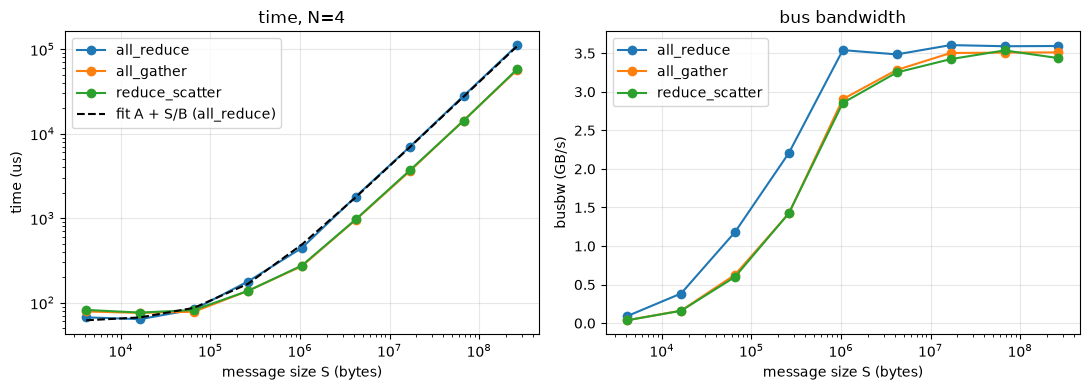

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for op in ("all_reduce", "all_gather", "reduce_scatter"):
    t = np.array(bench_res[op])
    ax[0].loglog(S, t * 1e6, "o-", label=op)
    ax[1].semilogx(S, S / t * busbw_factor(op, N) / 1e9, "o-", label=op)
ax[0].loglog(S, (A + S / B) * 1e6, "k--", label="fit A + S/B (all_reduce)")
ax[0].set(xlabel="message size S (bytes)", ylabel="time (us)", title=f"time, N={N}")
ax[1].set(xlabel="message size S (bytes)", ylabel="busbw (GB/s)", title="bus bandwidth")
for a in ax:
    a.legend()
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Read the plot.** Below roughly 100 KB the time is flat: latency dominates and busbw is tiny. Above a few MB the
curve becomes linear in $S$ and busbw saturates. On this box it saturates at a few GB/s (compare with your printed
fit), well under the PCIe link speed. Every byte goes GPU → host shared memory → GPU, and NCCL's SHM transport
copies through CPU memory.

**Why communication dominates (the number to remember).** One step of data-parallel training on a 1B-parameter
model in bf16 all-reduces $S = 2$ GB of gradients. Time $\approx 2\frac{N-1}{N} S / \text{busbw}$:

In [14]:
S_grad = 2e9
nvlink_bus = 370e9   # achieved intra-node all-reduce busbw on 8xH100 (scaling-book Part 12); peak 450 GB/s/direction
ib_bus = 50e9        # one 400 Gb/s NDR NIC per GPU (scaling-book Part 12)
for name, bw, n in [("this box (measured)", bus_inf, N), ("8xH100 NVSwitch", nvlink_bus, 8),
                    ("H100 nodes over IB", ib_bus, 64)]:
    t = 2 * (n - 1) / n * S_grad / bw
    print(f"{name:22s} N={n:3d}  busbw {bw/1e9:7.1f} GB/s  ->  all-reduce of 2 GB grads: {t*1e3:8.1f} ms")
print(f"ratio NVSwitch / this box: {nvlink_bus / bus_inf:.0f}x")

this box (measured)    N=  4  busbw     3.7 GB/s  ->  all-reduce of 2 GB grads:    815.1 ms
8xH100 NVSwitch        N=  8  busbw   370.0 GB/s  ->  all-reduce of 2 GB grads:      9.5 ms
H100 nodes over IB     N= 64  busbw    50.0 GB/s  ->  all-reduce of 2 GB grads:     78.8 ms
ratio NVSwitch / this box: 101x


Compare with compute. A 1B-parameter model at 4096 tokens per GPU needs about
$6 \cdot 10^9 \cdot 4096 \approx 2.5\cdot 10^{13}$ FLOPs per step (the 6ND rule from the single-GPU FLOPs/MFU lab). On a 3090 (dense bf16 tensor
peak 71 TFLOP/s, GA102 whitepaper) that is ≥ 0.35 s, the same order as the all-reduce above. On an H100
(990 TFLOP/s) it is ≥ 25 ms, against ~10 ms for the NVSwitch all-reduce. The ratio of compute time to
communication time drives the rest of the track: overlap (G1.11), sharding (G1.12), keeping tensor parallelism
inside NVLink (G1.13), and communicating rarely (DiLoCo, G1.21).

## Say it out loud
1. Define broadcast, reduce, all-reduce, reduce-scatter, all-gather and all-to-all in one sentence each. Which
   two compose into an all-reduce, and where does that identity show up in practice?
2. Derive the bytes each rank sends in a ring all-reduce. Why is it at most $2S$ regardless of $N$, and why is a
   parameter-server/reduce-to-root design worse?
3. Write the α–β cost of ring vs tree all-reduce. Which wins for an 8 KB tensor on 1024 GPUs, and which for 1 GB?
4. What are algbw and busbw, and why do nccl-tests multiply all-reduce algbw by $2(N-1)/N$?
5. `dist.all_reduce(t, async_op=True)` returns a work handle. What does `work.wait()` guarantee with NCCL, and why
   do you still need `torch.cuda.synchronize()` before reading a timer?
6. Name three ways to hang an NCCL job.
7. On this machine `can_device_access_peer` is False. What path does an all-reduce take, what bandwidth did you
   measure, and what would NVLink/NVSwitch change?
8. An all-to-all moves the same bytes per rank as a reduce-scatter. Why is it nonetheless often slower across
   nodes than a ring collective?

<details><summary>Model answers</summary>

1. broadcast: one rank's tensor copied to all. reduce: elementwise op over all ranks' tensors, result on one
   rank. all-reduce: the same, result on every rank. reduce-scatter: reduce, then rank $r$ keeps only chunk $r$.
   all-gather: concatenate every rank's chunk on every rank. all-to-all: rank $i$ sends its chunk $j$ to rank $j$
   (a distributed transpose). all-reduce = reduce-scatter + all-gather. This is how NCCL's ring works, and ZeRO/FSDP
   put the optimizer step between the halves (G1.12). Sequence parallelism splits Megatron's all-reduce the same
   way (G1.13).
2. $2(N-1)$ steps, each sending one $S/N$ chunk, so $2(N-1)S/N < 2S$. Every link carries the same load
   simultaneously, so time is $\approx 2S/B$ independent of $N$ (bandwidth term). With reduce-to-root, the root
   receives $(N-1)S$ and sends $(N-1)S$ through one link, so time grows linearly in $N$. Patarasuk & Yuan 2009 prove
   $2\frac{N-1}{N}S$ is the minimum per-rank traffic for all-reduce.
3. Ring: $2(N-1)\alpha + 2\frac{N-1}{N}S\beta$. Tree / recursive doubling: $\log_2N\,(\alpha + S\beta)$, and
   Rabenseifner gets $2\log_2N\,\alpha + 2\frac{N-1}{N}S\beta$. For 8 KB on 1024 GPUs the latency term dominates: ring
   pays $2046\alpha$ vs $\sim 10$-$20\alpha$, so tree. For 1 GB the bandwidth term dominates and ring (or
   Rabenseifner) is optimal. NCCL switches algorithm by size (it also has tree and, on NVSwitch, NVLS algorithms).
4. algbw $= S/t$. busbw rescales it to the traffic that actually crosses each link: a ring all-reduce sends
   $2(N-1)/N \cdot S$ per rank, so busbw = algbw · $2(N-1)/N$, which is ≈ link bandwidth when the collective is
   bandwidth-bound and stays comparable as $N$ changes (nccl-tests PERFORMANCE.md).
5. With NCCL, `wait()` makes the *current CUDA stream* wait for the collective's stream, so later kernels see the
   result. It does not block the CPU until the data has arrived. GPU work is asynchronous, so a wall-clock timer
   needs `torch.cuda.synchronize()` (CS336 A2 §5.1.1 makes the same point). With Gloo, `wait()` blocks the CPU.
6. (a) Ranks call collectives in a different order or one rank skips one (e.g. a data-dependent `if`, uneven
   numbers of batches per rank). (b) Mismatched shapes or dtypes. (c) Two ranks bound to the same GPU (forgot
   `set_device`), or blocking `send` on every rank with no matching `recv` posted. DDP's
   `find_unused_parameters` errors and the uneven-input `join()` context exist because of (a).
7. GPU → pinned host shared-memory buffer → GPU (NCCL `SHM/direct` transport), twice over PCIe 4.0 x16 plus a CPU-memory
   copy. Measured busbw saturates at a few GB/s with tens of µs latency. NVLink-4 + NVSwitch gives 450 GB/s per GPU
   per direction (~370 GB/s achieved all-reduce busbw), about 100× more. That is the difference between communication
   hiding under compute and dominating it.
8. All-to-all has $N-1$ distinct destinations per rank, so it is $N-1$ small point-to-point flows rather than
   pipelined neighbor transfers. Per-message latency counts $N-1$ times, flows contend in the network core (bisection
   bandwidth, not neighbor links), and the splits are often uneven (MoE routing). Ring collectives only use
   neighbor links, which map well onto NVLink rings and rail-optimized IB fabrics.
</details>

In [15]:
s.finish(lookups=0, score=None, notes="")

[G1.10] done in 0.5 min (within target 100 min)


0.5265870213508606